# PTB-XL ECG-Deli Feature Importance: Core 177 vs Full 531 (CUDA)

This notebook analyzes the `ecgdeli_features.csv` extracted from the PTB-XL dataset to identify the most critical ECG features for detecting Myocardial Infarction (MI).

It runs three separate experiments:
1. **Core 177 Features Only**: Analyzing only the base morphological extractions (ignoring downstream statistical aggregates like `_iqr` and `_count`).
2. **Full 531 Features**: Analyzing the full dataset (Core + IQR + Count) as independent features.
3. **Aggregated Family Importance (Combined)**: Training on all 531 features, but mathematically combining the importances of the base feature + its `_iqr` + its `_count` to find the true overall predictive power of the feature family.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
import re
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

# Set styling
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context('notebook')


## 1. Load Labels and Extract 'MI' Class


In [2]:
db_path = r'C:/Users/Acer/Desktop/Capstone/Capstone/data/raw/PTB-XL-1.0.3/ptbxl_database.csv'
scp_path = r'C:/Users/Acer/Desktop/Capstone/Capstone/data/raw/PTB-XL-1.0.3/scp_statements.csv'

db = pd.read_csv(db_path, index_col='ecg_id')
db['scp_codes'] = db['scp_codes'].apply(ast.literal_eval)

agg_df = pd.read_csv(scp_path, index_col=0)
mi_keys = agg_df[agg_df.diagnostic_class == 'MI'].index.tolist()

db['is_MI'] = db['scp_codes'].apply(lambda d: 1 if any(k in mi_keys for k in d.keys()) else 0)
print(f"Total Records: {len(db)} | Total MI Positive: {db['is_MI'].sum()}")


Total Records: 21799 | Total MI Positive: 5469


## 2. Load and Split Features


In [3]:
features_path = r'C:/Users/Acer/Desktop/Capstone/Capstone/data/raw/PTB-XL+-1.0.1/features/ecgdeli_features.csv'
features = pd.read_csv(features_path)

data = pd.merge(features, db[['is_MI']], left_on='ecg_id', right_index=True, how='inner')
y = data['is_MI']

# FULL 531 FEATURES
X_full = data.drop(columns=['ecg_id', 'is_MI'])

# ONLY 177 CORE FEATURES (No IQR, No Count)
agg_cols = [col for col in X_full.columns if '_iqr' in col.lower() or '_count' in col.lower()]
X_core = X_full.drop(columns=agg_cols)

print(f"Full Features Shape: {X_full.shape}")
print(f"Core Features Shape: {X_core.shape}")


Full Features Shape: (21799, 531)
Core Features Shape: (21799, 177)


## 3. Experiment Engine
We define a function to run 5-Fold Stratified CV with XGBoost and compute Permutation Importances.


In [4]:
def run_experiment(X, y, exp_name):
    print(f"\n==================================================")
    print(f"RUNNING EXPERIMENT: {exp_name}")
    print(f"==================================================")
    
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    roc_aucs, pr_aucs = [], []
    importances_list = []

    fold = 1
    for train_idx, test_idx in skf.split(X, y):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        imputer = SimpleImputer(strategy='median')
        X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)
        X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X.columns)
        
        scale_pos = (len(y_train) - y_train.sum()) / y_train.sum()
        
        xgb = XGBClassifier(
            n_estimators=100, 
            max_depth=6, 
            scale_pos_weight=scale_pos, 
            tree_method='hist', 
            device='cuda', # Train lightning fast on the GPU
            random_state=42, 
            n_jobs=8
        )
        xgb.fit(X_train_imp, y_train)
        
        y_pred_proba = xgb.predict_proba(X_test_imp)[:, 1]
        roc_aucs.append(roc_auc_score(y_test, y_pred_proba))
        pr_aucs.append(average_precision_score(y_test, y_pred_proba))
        
        # Switch model inference to CPU specifically for permutation importance
        # This allows us to use n_jobs=-1 to run permutations in parallel across all CPU cores without CUDA crashes!
        xgb.set_params(device='cpu')
        result = permutation_importance(xgb, X_test_imp, y_test, n_repeats=3, random_state=42, n_jobs=-1, scoring='average_precision')
        importances_list.append(result.importances_mean)
        fold += 1

    print(f"[{exp_name}] Average ROC-AUC: {np.mean(roc_aucs):.3f}")
    print(f"[{exp_name}] Average PR-AUC:  {np.mean(pr_aucs):.3f}")

    mean_importances = np.mean(importances_list, axis=0)
    
    # Return raw features and importances before sorting so we can do custom grouping downstream
    return X.columns.tolist(), mean_importances.tolist()

def plot_and_save(features, importances, exp_name):
    # Sort
    indices = np.argsort(importances)[::-1]
    sorted_features = np.array(features)[indices]
    sorted_importances = np.array(importances)[indices]
    
    # Save CSV
    importance_df = pd.DataFrame({'Feature': sorted_features, 'Importance': sorted_importances})
    safe_name = exp_name.replace(" ", "_").replace("(", "").replace(")", "").replace("+", "and")
    csv_name = f'feature_importances_{safe_name}.csv'
    importance_df.to_csv(csv_name, index=False)
    
    # Save Plot
    top_k = 50
    if len(sorted_features) < 50:
        top_k = len(sorted_features)
    
    plt.figure(figsize=(12, 12))
    sns.barplot(x=sorted_importances[:top_k], y=sorted_features[:top_k], hue=sorted_features[:top_k], palette='viridis', legend=False)
    plt.title(f'Top {top_k} Features - {exp_name}', fontsize=16)
    plt.xlabel('Mean Decrease in PR-AUC', fontsize=14)
    plt.ylabel('Feature Name', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    print(f"\n[{exp_name}] TOP 50 FEATURES:")
    print(sorted_features[:top_k].tolist())


## 4. Run Experiment 1: Core 177 Features Only



RUNNING EXPERIMENT: Core 177 Features Only
[Core 177 Features Only] Average ROC-AUC: 0.922
[Core 177 Features Only] Average PR-AUC:  0.826


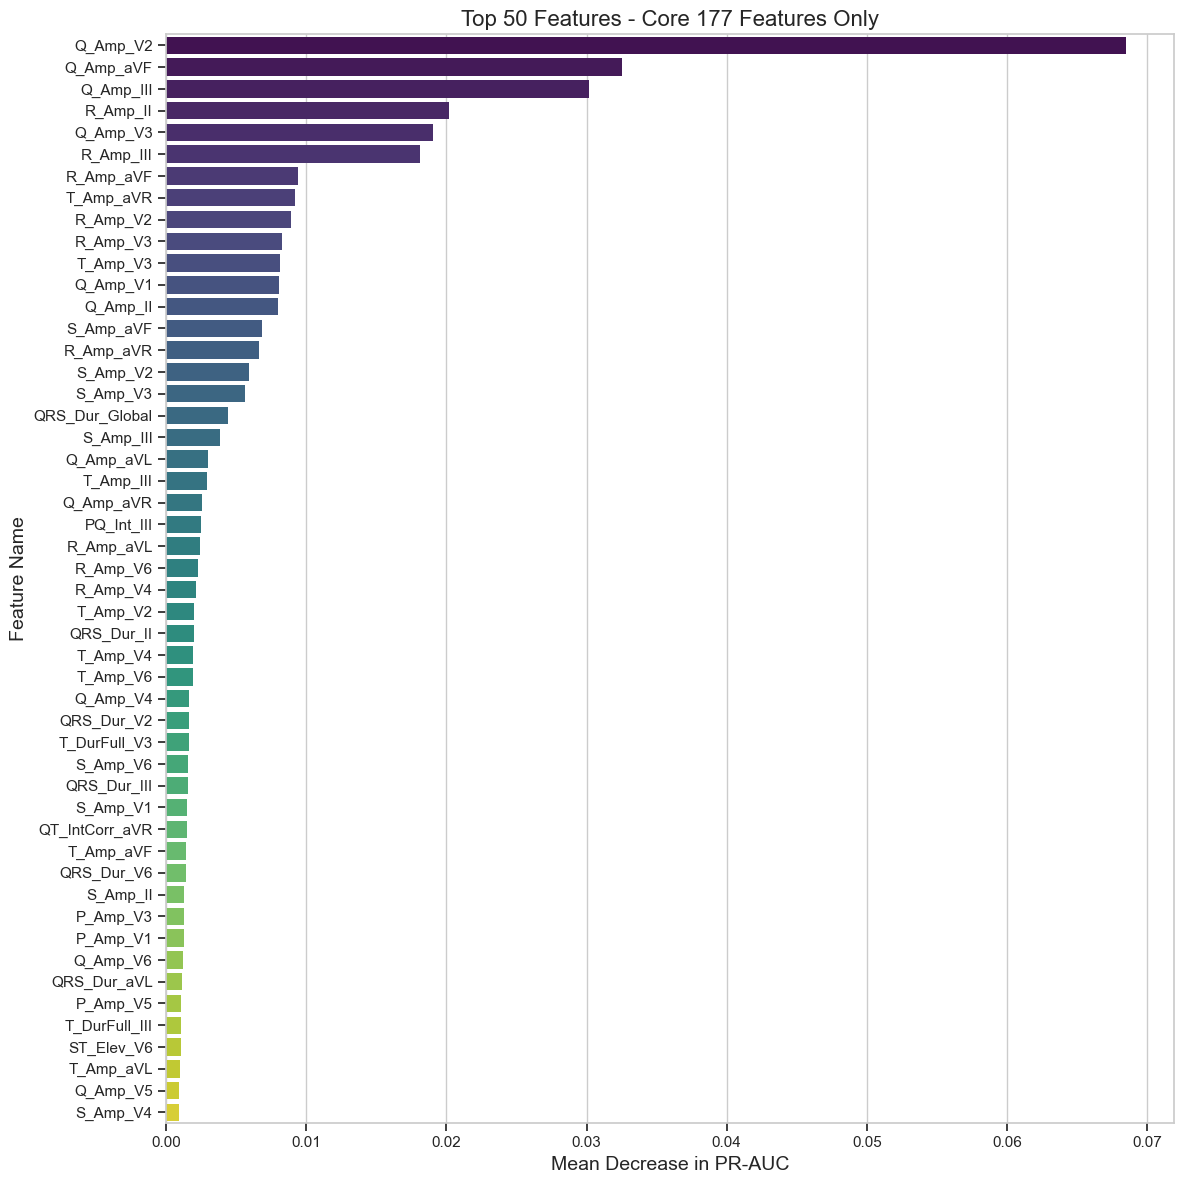


[Core 177 Features Only] TOP 50 FEATURES:
['Q_Amp_V2', 'Q_Amp_aVF', 'Q_Amp_III', 'R_Amp_II', 'Q_Amp_V3', 'R_Amp_III', 'R_Amp_aVF', 'T_Amp_aVR', 'R_Amp_V2', 'R_Amp_V3', 'T_Amp_V3', 'Q_Amp_V1', 'Q_Amp_II', 'S_Amp_aVF', 'R_Amp_aVR', 'S_Amp_V2', 'S_Amp_V3', 'QRS_Dur_Global', 'S_Amp_III', 'Q_Amp_aVL', 'T_Amp_III', 'Q_Amp_aVR', 'PQ_Int_III', 'R_Amp_aVL', 'R_Amp_V6', 'R_Amp_V4', 'T_Amp_V2', 'QRS_Dur_II', 'T_Amp_V4', 'T_Amp_V6', 'Q_Amp_V4', 'QRS_Dur_V2', 'T_DurFull_V3', 'S_Amp_V6', 'QRS_Dur_III', 'S_Amp_V1', 'QT_IntCorr_aVR', 'T_Amp_aVF', 'QRS_Dur_V6', 'S_Amp_II', 'P_Amp_V3', 'P_Amp_V1', 'Q_Amp_V6', 'QRS_Dur_aVL', 'P_Amp_V5', 'T_DurFull_III', 'ST_Elev_V6', 'T_Amp_aVL', 'Q_Amp_V5', 'S_Amp_V4']


In [5]:
features_core, importances_core = run_experiment(X_core, y, "Core 177 Features Only")
plot_and_save(features_core, importances_core, "Core 177 Features Only")


## 5. Run Experiment 2: Full 531 Features (Core + IQR + Count)



RUNNING EXPERIMENT: Full 531 Features
[Full 531 Features] Average ROC-AUC: 0.923
[Full 531 Features] Average PR-AUC:  0.828


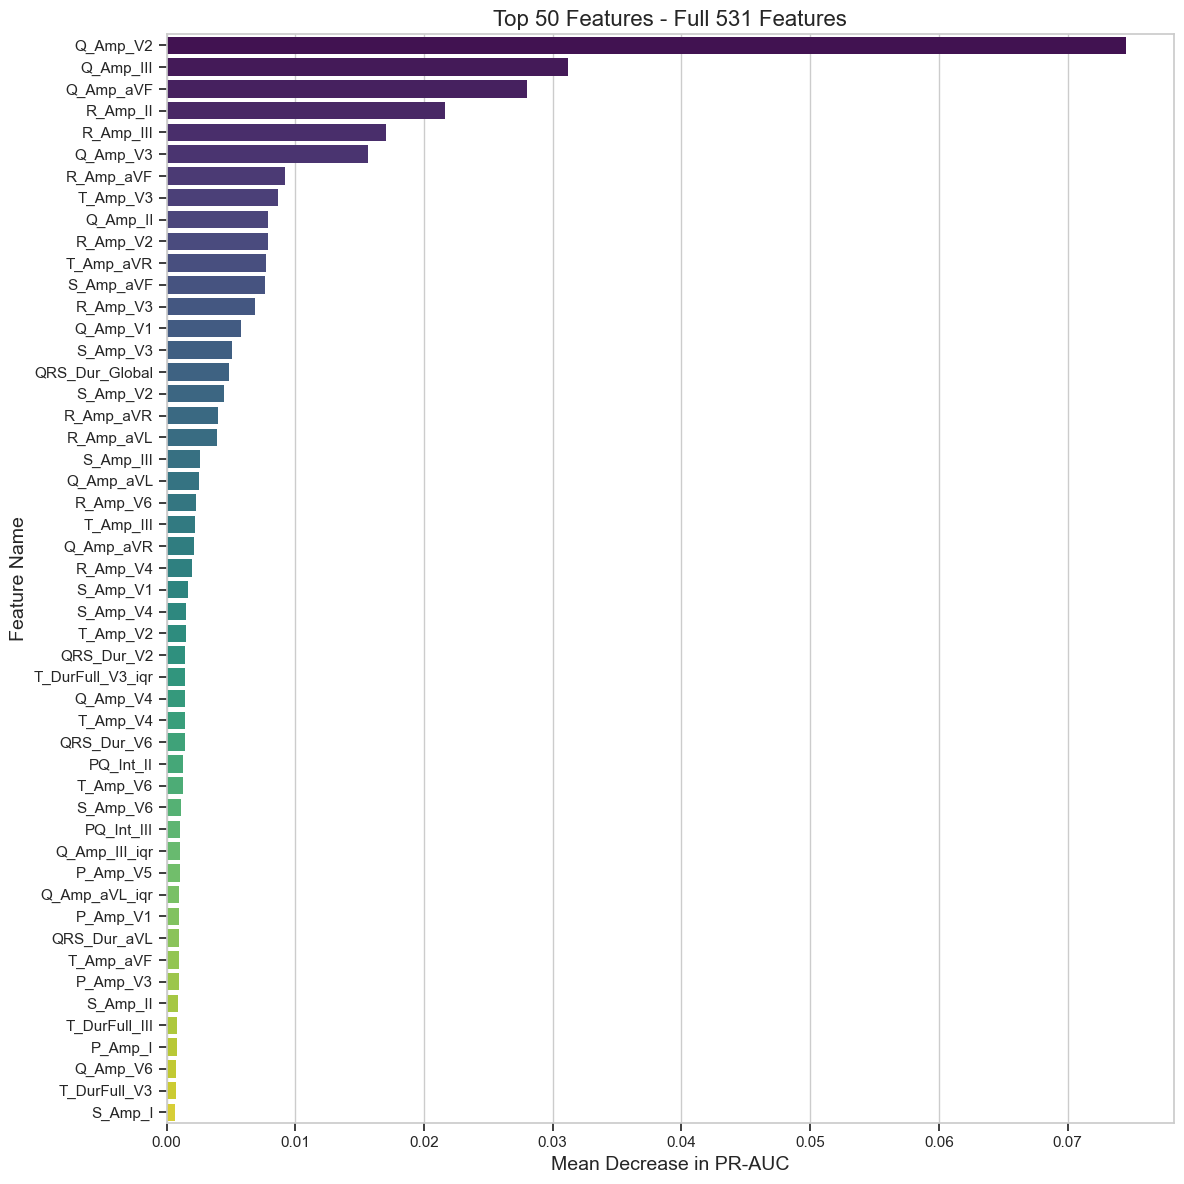


[Full 531 Features] TOP 50 FEATURES:
['Q_Amp_V2', 'Q_Amp_III', 'Q_Amp_aVF', 'R_Amp_II', 'R_Amp_III', 'Q_Amp_V3', 'R_Amp_aVF', 'T_Amp_V3', 'Q_Amp_II', 'R_Amp_V2', 'T_Amp_aVR', 'S_Amp_aVF', 'R_Amp_V3', 'Q_Amp_V1', 'S_Amp_V3', 'QRS_Dur_Global', 'S_Amp_V2', 'R_Amp_aVR', 'R_Amp_aVL', 'S_Amp_III', 'Q_Amp_aVL', 'R_Amp_V6', 'T_Amp_III', 'Q_Amp_aVR', 'R_Amp_V4', 'S_Amp_V1', 'S_Amp_V4', 'T_Amp_V2', 'QRS_Dur_V2', 'T_DurFull_V3_iqr', 'Q_Amp_V4', 'T_Amp_V4', 'QRS_Dur_V6', 'PQ_Int_II', 'T_Amp_V6', 'S_Amp_V6', 'PQ_Int_III', 'Q_Amp_III_iqr', 'P_Amp_V5', 'Q_Amp_aVL_iqr', 'P_Amp_V1', 'QRS_Dur_aVL', 'T_Amp_aVF', 'P_Amp_V3', 'S_Amp_II', 'T_DurFull_III', 'P_Amp_I', 'Q_Amp_V6', 'T_DurFull_V3', 'S_Amp_I']


In [6]:
features_full, importances_full = run_experiment(X_full, y, "Full 531 Features")
plot_and_save(features_full, importances_full, "Full 531 Features")


## 6. Run Experiment 3: Aggregated Family Importance
This takes the importances from Experiment 2 (Full 531), and mathematically combines the importances of every base feature + its `_iqr` + its `_count` to get the true combined predictive power of the feature family!


Combined 531 features into 177 core families.


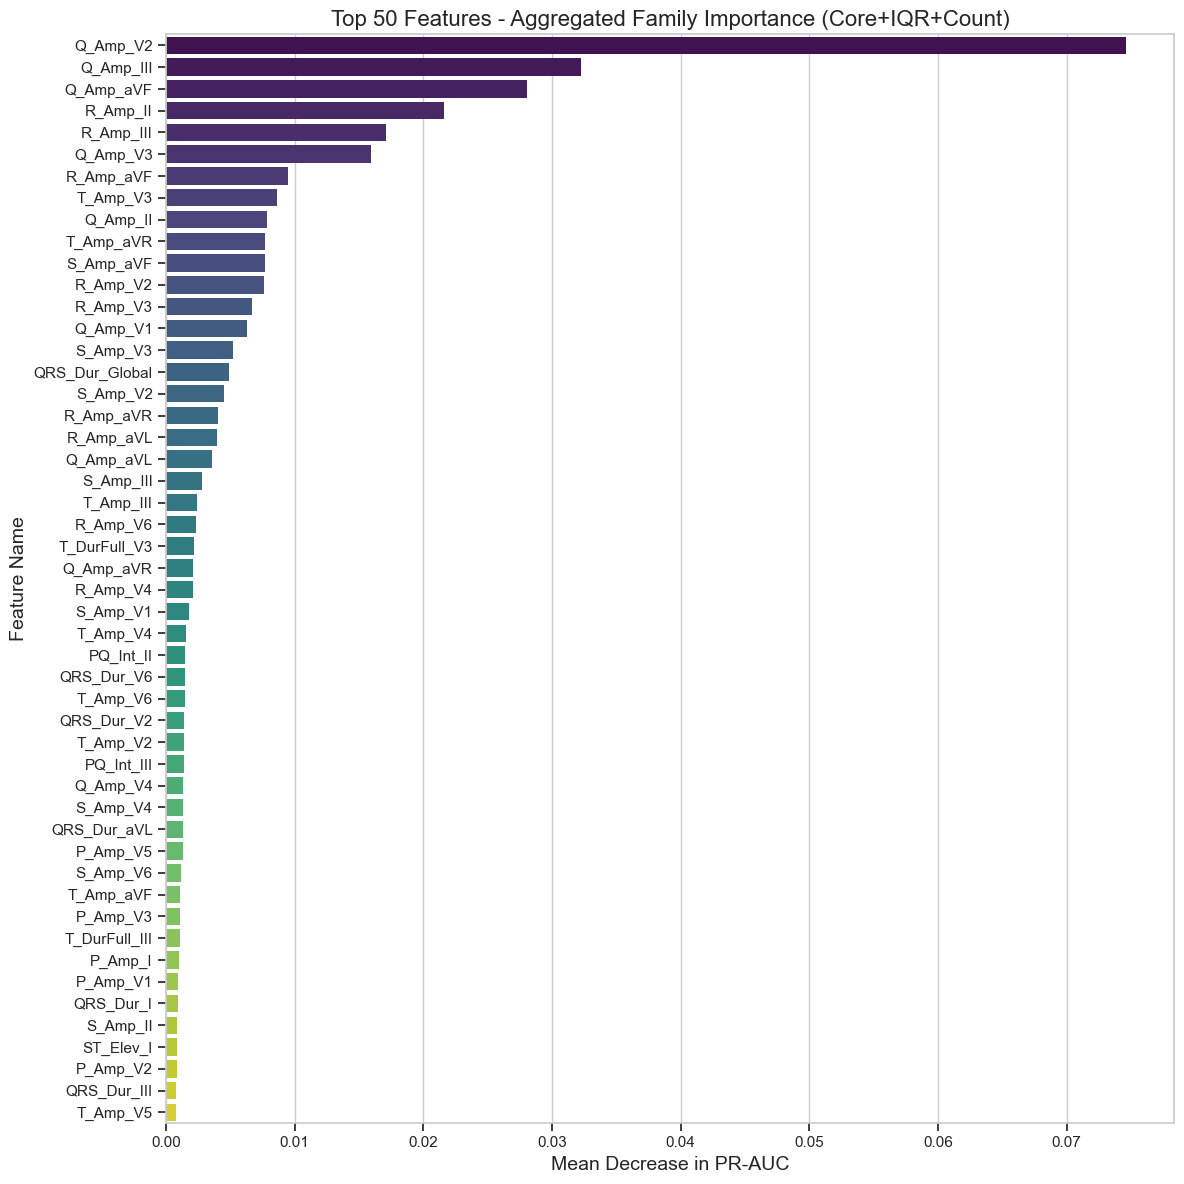


[Aggregated Family Importance (Core+IQR+Count)] TOP 50 FEATURES:
['Q_Amp_V2', 'Q_Amp_III', 'Q_Amp_aVF', 'R_Amp_II', 'R_Amp_III', 'Q_Amp_V3', 'R_Amp_aVF', 'T_Amp_V3', 'Q_Amp_II', 'T_Amp_aVR', 'S_Amp_aVF', 'R_Amp_V2', 'R_Amp_V3', 'Q_Amp_V1', 'S_Amp_V3', 'QRS_Dur_Global', 'S_Amp_V2', 'R_Amp_aVR', 'R_Amp_aVL', 'Q_Amp_aVL', 'S_Amp_III', 'T_Amp_III', 'R_Amp_V6', 'T_DurFull_V3', 'Q_Amp_aVR', 'R_Amp_V4', 'S_Amp_V1', 'T_Amp_V4', 'PQ_Int_II', 'QRS_Dur_V6', 'T_Amp_V6', 'QRS_Dur_V2', 'T_Amp_V2', 'PQ_Int_III', 'Q_Amp_V4', 'S_Amp_V4', 'QRS_Dur_aVL', 'P_Amp_V5', 'S_Amp_V6', 'T_Amp_aVF', 'P_Amp_V3', 'T_DurFull_III', 'P_Amp_I', 'P_Amp_V1', 'QRS_Dur_I', 'S_Amp_II', 'ST_Elev_I', 'P_Amp_V2', 'QRS_Dur_III', 'T_Amp_V5']


In [8]:
import re

# We map every feature name to its base name (stripping _iqr and _count)
grouped_importances = {}

for feat, imp in zip(features_full, importances_full):
    # Strip _iqr and _count (case insensitive)
    base_name = re.sub(r'_(iqr|count)$', '', feat, flags=re.IGNORECASE)
    
    if base_name not in grouped_importances:
        grouped_importances[base_name] = 0.0
    grouped_importances[base_name] += imp

# Extract as lists
grouped_features = list(grouped_importances.keys())
grouped_imp_values = list(grouped_importances.values())

print(f"Combined 531 features into {len(grouped_features)} core families.")
plot_and_save(grouped_features, grouped_imp_values, "Aggregated Family Importance (Core+IQR+Count)")
